# Scratch Space

In [21]:
import numpy as np
import pandas as pd
import math
import tqdm
import itertools
from functools import cache
import matplotlib.pyplot as plt
from matplotlib import ticker as mticks


In [ ]:
def bitwise_add(a:int, b:int):
	def _add(a,b):
		carry = 0
		res = 0
		i = 1
		while i<=a or i<=b:
			ai = a//i & 1
			bi = b//i & 1

			ri = ai ^ bi ^ carry # tests odd bits
			carry = (ai & bi) | carry & (ai|bi)

			res |= ri * i
			print(f'{ai=}, {bi=}')
			print(f'{i:2d} {res=:04b}, {carry=}')
			
			i <<= 1
		res |= carry * i
		return res



bitwise_add(-3,-2)

a=-011
b=-010
a=0011
b=0010
ai=1, bi=0
 1 res=0001, carry=0
ai=1, bi=1
 2 res=0001, carry=1
res=   101
5 1


In [133]:
t10 = (1 << 10) - 1
print(f'{t10}={t10:012b}')
g = -5

# properly complement
gt = g + t10


print(f'{g:12b}')
print(f'{gt:12b}')

1023=001111111111
        -101
  1111111010


In [120]:
2**10

1024

# Araxxor Temp

In [213]:
import scipy
sspcomb = scipy.special.comb

def finish_at(k:int):
	r = 1/200
	prek = k-1
	two_rate = np.pow(1-r, prek-2)*np.power(r,2) * sspcomb(prek, 2, exact=True)

	return two_rate * r

# def finish_by(k:int):
# 	r = 1/200
# 	return sspcomb(k, 3, exact=True)*np.power(r,3)*np.power(1-r, k-3)

def finish_cdf(K:int):
	r = 1/200
	c = 1
	for k in range(3):
		c -= sspcomb(K,k)*np.power(r,k)*np.power(1-r, K-k)
	return c

K = np.arange(0,1201)

a = np.asarray([ finish_at(k) for k in K ])
a_cs = np.cumsum(a)
acp = np.asarray([ finish_cdf(k) for k in K ])
# b = np.asarray([ finish_by(k) for k in K ])

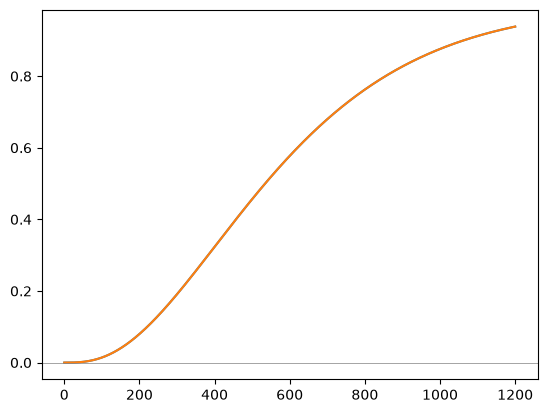

In [214]:
expectation = np.argmax(a)

fig, ax = plt.subplots()

ax.plot(K,a_cs)
ax.plot(K,acp)

# ax.set_ylim([-0.05,1.05])
ax.axhline(0.0, color='gray', linewidth=0.5,)
# ax.axhline(1.0, color='gray', linewidth=0.5,)

In [219]:
for k in range(3,8):
	print( f'{k:4d}: {a_cs[k]:10.8f} {acp[k]:10.8f}' )

print('             ...')
for k in K[-5:]:
	print( f'{k:4d}: {a_cs[k]:10.8f} {acp[k]:10.8f}' )

   3: 0.00000013 0.00000012
   4: 0.00000050 0.00000050
   5: 0.00000124 0.00000124
   6: 0.00000247 0.00000247
   7: 0.00000431 0.00000431
             ...
1196: 0.93758281 0.93758281
1197: 0.93780758 0.93780758
1198: 0.93803160 0.93803160
1199: 0.93825487 0.93825487
1200: 0.93847740 0.93847740


$$ CDF(K) = \sum_{k=0}^{K} \binom{k-1}{2}(1-r)^{k-3}r^3 $$
$$ = \sum_{k=3}^{K} \frac{(k-1)(k-2)}{2}(1-r)^{k-3}r^3 $$
$$ = \frac{1}{2}r^3 sum_{k=3}^{K} (k-1)(k-2)(1-r)^{k-3} $$
$$ = \frac{1}{2}(1-p)^3 \sum_{k=3}^{K} (k-1)(k-2)p^{k-3} $$
$$ = \frac{1}{2}(1-p)^3 \sum_{k=3}^{K} \frac{d}{dp}(k-1)p^{k-2} $$
$$ = \frac{1}{2}(1-p)^3 \sum_{k=3}^{K} \frac{d^2}{dp^2}p^{k-1} $$
$$ = \frac{1}{2}(1-p)^3 \frac{d^2}{dp^2} \sum_{k=3}^{K} p^{k-1} $$

$$ = \frac{1}{2}(1-p)^3 \frac{d^2}{dp^2} \left(\frac{p^2-p^K}{1-p}\right) $$

$$ = \frac{1}{2}(1-p)^3 \frac{d}{dp} \frac{(2p-Kp^{K-1})(1-p) - (p^2-p^K)(-1)}{(1-p)^2} $$

$$ = \frac{1}{2}(1-p)^3 \frac{d}{dp} \frac{ 2p-Kp^{K-1} - 2p^2 + Kp^K + p^2-p^K}{(1-p)^2} $$

$$ = \frac{1}{2}(1-p)^3 \frac{d}{dp} \frac{ (K-1)p^K - Kp^{K-1} - p^2 + 2p}{(1-p)^2} $$

$$ = \frac{1}{2}(1-p)^3 \frac{ (K(K-1)p^{K-1} - K(K-1)p^{K-2} - 2p + 2)(1-2p+p^2) - ((K-1)p^K - Kp^{K-1} - p^2 + 2p)(-2(1-p)) }{(1-p)^4} $$

$$ = \frac{1}{2}(1-p)^3 \frac{ (K(K-1)p^{K-1} - K(K-1)p^{K-2} - 2p + 2)(1-2p+p^2) - ((K-1)p^K - Kp^{K-1} - p^2 + 2p)(-2(1-p)) }{(1-p)^4} $$


$$
% left term
% K(K-1)p^{K-1} - K(K-1)p^{K-2} - 2p + 2 - 2K(K-1)p^{K} + 2K(K-1)p^{K-1} + 4p^2 - 4p + K(K-1)p^{K+1} - K(K-1)p^{K} - 2p^3 + 2p^2

% K(K-1)p^{K+1} - 3K(K-1)p^{K} + 3K(K-1)p^{K-1} - K(K-1)p^{K-2} - 2p^3 + 6p^2 - 6p + 2

% K(K-1)p^{K-2}\left( p^3 -3p^2 + 3p - 1\right) - 2(p^3 - 3p^2 + 3p - 1)

% K(K-1)p^{K-2}(p-1)^3 - 2(p-1)^3
% (K(K-1)p^{K-2} - 2)(p-1)^3
$$

$$
% right term
% ((K-1)p^K - Kp^{K-1} - p^2 + 2p)(-2(1-p))

((K-1)p^K - Kp^{K-1} - p^2 + 2p)(2p-2)



$$

In [ ]:

sspcomb(6,2, exact=True)

15

In [196]:
acp[600]

np.float64(57.737150671719725)

In [2]:
eval('list(range(1,11))')

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

In [11]:
def sum_of_powers(R, p):
    x = np.arange(1,R+1)
    x = np.pow(x, p)
    return np.cumsum(x)

sum_of_powers(5, 2)

R = 5
p = 2
for i,cs in enumerate(sum_of_powers(R, p)):
    k = i+1
    t = k*(k+1)*(2*k+1)//6
    print(f'{k=} | {cs:3d} {t:3d} {t==cs}')

k=1 |   1   1 True
k=2 |   5   5 True
k=3 |  14  14 True
k=4 |  30  30 True
k=5 |  55  55 True
